<a href="https://colab.research.google.com/github/nisaerdemli/imageprocessing/blob/main/hafta10g%C3%B6rev4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

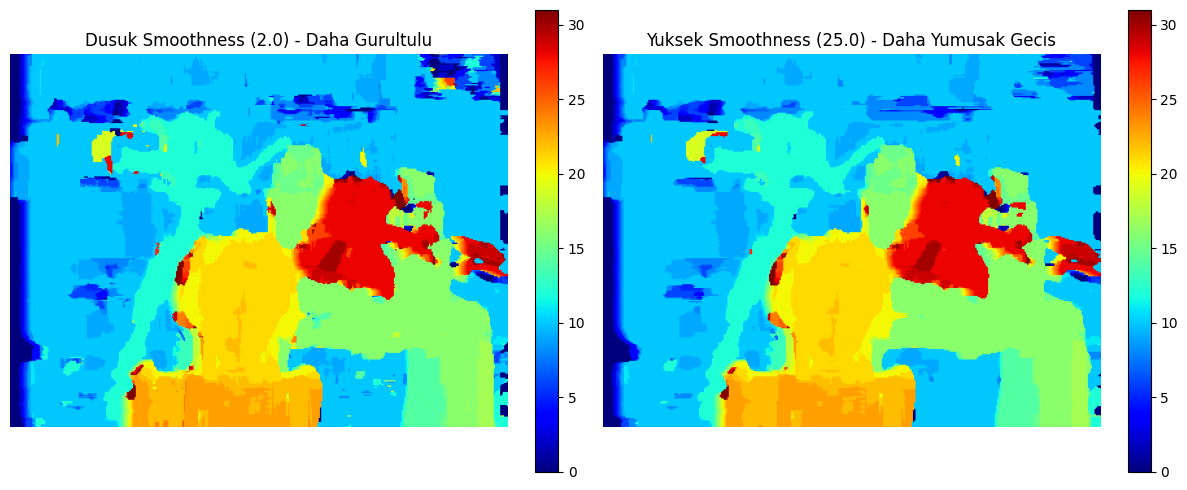

In [1]:
from pathlib import Path
import urllib.request
import zipfile
import cv2
import matplotlib.pyplot as plt
import numpy as np

url = "https://vision.middlebury.edu/stereo/data/scenes2001/data/tsukuba/tsukuba.zip"
zip_path = Path("tsukuba.zip")
extract_dir = Path("tsukuba_data")
valid_exts = {".ppm", ".pgm", ".png", ".jpg", ".jpeg"}

img_files = (
    sorted([p for p in extract_dir.rglob("*") if p.suffix.lower() in valid_exts])
    if extract_dir.exists()
    else []
)

if len(img_files) < 3:
  if zip_path.exists() and not zipfile.is_zipfile(zip_path):
    zip_path.unlink()
  if not zip_path.exists():
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=30) as resp, open(
        zip_path, "wb"
    ) as f:
      f.write(resp.read())
  with zipfile.ZipFile(zip_path, "r") as zf:
    zf.extractall(extract_dir)
  img_files = sorted(
      [p for p in extract_dir.rglob("*") if p.suffix.lower() in valid_exts]
  )

left_img = cv2.imread(str(img_files[0]))
right_img = cv2.imread(str(img_files[2]))
left_gray = cv2.cvtColor(left_img, cv2.COLOR_BGR2GRAY).astype(np.float32)
right_gray = cv2.cvtColor(right_img, cv2.COLOR_BGR2GRAY).astype(np.float32)


def my_sgbc_matching(
    left: np.ndarray,
    right: np.ndarray,
    block_size: int = 11,
    max_disparity: int = 32,
    smoothness: float = 15.0,
) -> np.ndarray:
  """Yumusak gecis (smoothness) cezali kendi eslestirme algoritmasi."""
  h, w = left.shape
  cost_volume = np.full((h, w, max_disparity), np.inf, dtype=np.float32)
  kernel = (block_size, block_size)

  # 1. Her kayma (d) icin temel blok SAD maliyetini hesapla
  for d in range(max_disparity):
    if d == 0:
      shifted_r = right
    else:
      shifted_r = np.zeros_like(right)
      shifted_r[:, d:] = right[:, :-d]

    diff = np.abs(left - shifted_r)
    cost_volume[:, :, d] = cv2.boxFilter(diff, -1, kernel, normalize=False)

  # 2. Yatay hat boyunca komsu kayma farklarina yumusak gecis cezasi ekle
  agg_cost = np.zeros_like(cost_volume)
  agg_cost[:, 0, :] = cost_volume[:, 0, :]

  d_curr = np.arange(max_disparity)[None, :, None]  # (1, D, 1)
  d_prev = np.arange(max_disparity)[None, None, :]  # (1, 1, D)
  penalty_matrix = smoothness * np.abs(d_curr - d_prev)  # (1, D, D)

  for x in range(1, w):
    prev_cost = agg_cost[:, x - 1, :][:, None, :]  # (H, 1, D)
    best_prev_transition = np.min(prev_cost + penalty_matrix, axis=2)  # (H, D)
    agg_cost[:, x, :] = cost_volume[:, x, :] + best_prev_transition

  return np.argmin(agg_cost, axis=2).astype(np.float32)


disp_low_smooth = my_sgbc_matching(
    left_gray, right_gray, block_size=11, max_disparity=32, smoothness=2.0
)
disp_high_smooth = my_sgbc_matching(
    left_gray, right_gray, block_size=11, max_disparity=32, smoothness=25.0
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

im0 = axes[0].imshow(disp_low_smooth, cmap="jet")
axes[0].set_title("Dusuk Smoothness (2.0) - Daha Gurultulu")
axes[0].axis("off")
plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(disp_high_smooth, cmap="jet")
axes[1].set_title("Yuksek Smoothness (25.0) - Daha Yumusak Gecis")
axes[1].axis("off")
plt.colorbar(im1, ax=axes[1], fraction=0.046)

plt.tight_layout()
plt.show()